In [8]:
from tensorflow import keras
from keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

In [9]:
import numpy as np
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        sequence = np.asarray(sequence, dtype=np.int64)
        results[i, sequence] = 1.0
    return results

In [10]:
train_data = vectorize_sequences(train_data)
test_data = vectorize_sequences(test_data)
print(train_data[0])
train_labels = np.asarray(train_labels).astype("float32")
test_labels = np.asarray(test_labels).astype("float32")


[0. 1. 1. ... 0. 0. 0.]


In [11]:
original_model = keras.models.Sequential(layers=[
    keras.layers.Dense(16, activation="relu", input_shape=(10000,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])
original_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])

c:\Users\allou\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
smaller_model = keras.models.Sequential(layers=[
    keras.layers.Dense(4, activation="relu", input_shape=(10000,)),
    keras.layers.Dense(1, activation="sigmoid")
])
smaller_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
smaller_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 4)              │        40,004 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,009 (156.29 KB)

 Trainable params: 40,009 (156.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
original_model.summary()
#le modèle original a 16 neurones dans la première couche cachée et 16 neurones dans la deuxième couche cachée, tandis que le modèle plus petit a seulement 4 neurones dans la première couche cachée et aucune deuxième couche cachée. Cela signifie que le modèle plus petit a moins de paramètres à apprendre et est donc moins susceptible de surajuster les données d'entraînement.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
(x_test, y_test) = (test_data, test_labels)
(x_train, y_train) = (train_data, train_labels)
original_model.fit(train_data, train_labels, epochs=20, batch_size=512, validation_split=0.4,  validation_data=(x_test, y_test))
smaller_model.fit = smaller_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_test, y_test)
)

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.7764 - loss: 0.5209 - val_accuracy: 0.8714 - val_loss: 0.3730
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8969 - loss: 0.2926 - val_accuracy: 0.8887 - val_loss: 0.2907
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9198 - loss: 0.2218 - val_accuracy: 0.8827 - val_loss: 0.2935
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9331 - loss: 0.1868 - val_accuracy: 0.8864 - val_loss: 0.2836
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9422 - loss: 0.1643 - val_accuracy: 0.8736 - val_loss: 0.3275
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9499 - loss: 0.1454 - val_accuracy: 0.8804 - val_loss: 0.3095
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9546 - loss: 0.1312 - val_accuracy: 0.8758 - val_loss: 0.3347
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9596 - loss: 0.1191 - val_accuracy: 0.8761 - val_los

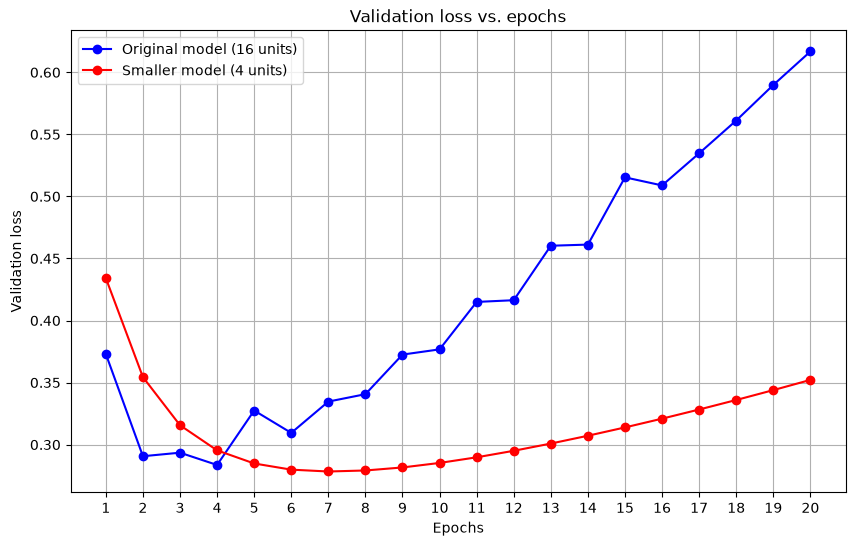

In [15]:

import matplotlib.pyplot as plt

# Validation loss for both models
original_val_loss = original_model.history.history['val_loss']
smaller_val_loss = smaller_model.history.history['val_loss']

epochs = range(1, 21)

plt.figure(figsize=(10, 6))
plt.plot(epochs, original_val_loss, 'b-o', label='Original model (16 units)')
plt.plot(epochs, smaller_val_loss, 'r-o', label='Smaller model (4 units)')

plt.xlabel('Epochs')
plt.ylabel('Validation loss')
plt.title('Validation loss vs. epochs')
plt.legend()
plt.xticks(epochs)
plt.grid(True)
plt.show()


Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - accuracy: 0.7764 - loss: 0.4951 - val_accuracy: 0.8768 - val_loss: 0.3225
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.8887 - loss: 0.2750 - val_accuracy: 0.8770 - val_loss: 0.2910
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.9087 - loss: 0.2215 - val_accuracy: 0.8866 - val_loss: 0.2701
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 120ms/step - accuracy: 0.9294 - loss: 0.1758 - val_accuracy: 0.8536 - val_loss: 0.3778
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.9449 - loss: 0.1386 - val_accuracy: 0.8808 - val_loss: 0.3120
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.9610 - loss: 0.1016 - val_accuracy: 0.8614 - val_loss: 0.4262
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 137ms/step - accuracy: 0.9746 - loss: 0.0709 - val_accuracy: 0.8593 - val_loss: 0.4615
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 148ms/step - accuracy: 0.9816 - loss: 0.0570 - val_accuracy: 0.8

Text(0.5, 1.0, 'Validation loss across epochs for bigger model')

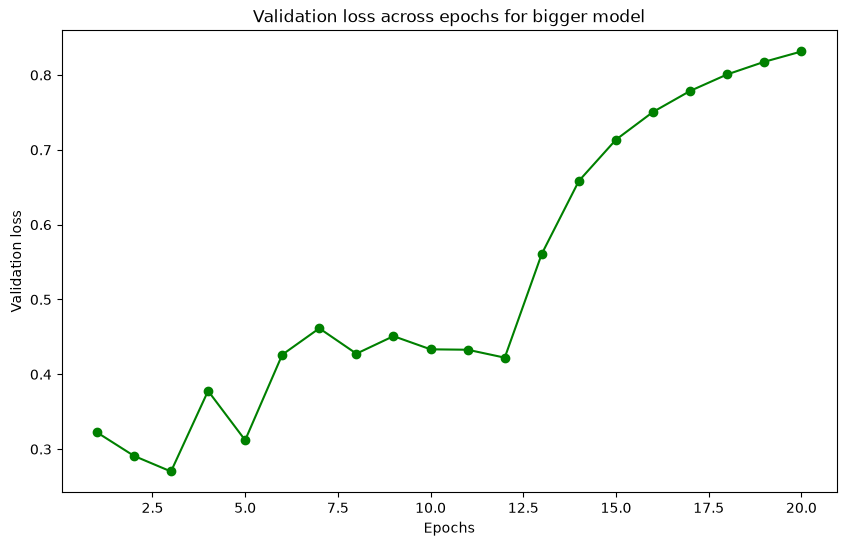

In [16]:
bigger_models=keras.models.Sequential(layers=[keras.layers.Dense(512,activation='relu',input_shape=(10000,)),keras.layers.Dense(512,activation='relu'),keras.layers.Dense(1,activation='sigmoid')])
bigger_models.compile(optimizer='rmsprop',loss='binary_crossentropy',metrics=['accuracy'])
bigger_models.fit(train_data,train_labels,epochs=20,batch_size=512,validation_split=0.4,validation_data=(x_test,y_test))
bigger_val_loss=bigger_models.history.history['val_loss']
epochs=range(1,21)
plt.figure(figsize=(10,6))
plt.plot(epochs,bigger_val_loss,'g-o',label='Bigger model (512 units)')
plt.xlabel('Epochs')
plt.ylabel('Validation loss')
plt.title('Validation loss across epochs for bigger model')

In [17]:
from tensorflow.keras import regularizers
original_model_with_l2 = keras.models.Sequential(layers=[
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(0.001), input_shape=(10000,)),
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(1, activation='sigmoid')
])

original_model_with_l2.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
original_model_with_l2.fit(x_train,y_train,epochs=20,batch_size=512,validation_data=(x_test,y_test))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.8118 - loss: 0.5139 - val_accuracy: 0.8806 - val_loss: 0.3906
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9000 - loss: 0.3277 - val_accuracy: 0.8868 - val_loss: 0.3395
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9192 - loss: 0.2748 - val_accuracy: 0.8888 - val_loss: 0.3279
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9261 - loss: 0.2519 - val_accuracy: 0.8870 - val_loss: 0.3328
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9323 - loss: 0.2375 - val_accuracy: 0.8668 - val_loss: 0.3847
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9362 - loss: 0.2277 - val_accuracy: 0.8829 - val_loss: 0.3468
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9405 - loss: 0.2198 - val_accuracy: 0.8802 - val_loss: 0.3555
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9416 - loss: 0.2149 - val_accuracy: 0.8724 - v

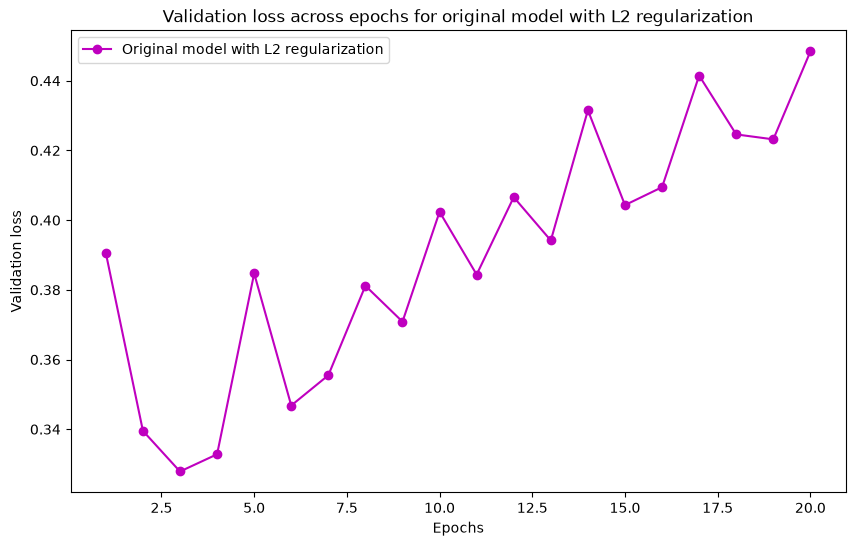

In [18]:
validation_loss_with_l2 = original_model_with_l2.history.history['val_loss']
epochs = range(1, 21)
plt.figure(figsize=(10, 6))
plt.plot(epochs, validation_loss_with_l2, 'm-o', label='Original model with L2 regularization')
plt.xlabel('Epochs')
plt.ylabel('Validation loss')
plt.title('Validation loss across epochs for original model with L2 regularization')
plt.legend()
plt.show()

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7842 - loss: 0.9578 - val_accuracy: 0.8542 - val_loss: 0.6486
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8580 - loss: 0.6088 - val_accuracy: 0.8648 - val_loss: 0.5790
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8665 - loss: 0.5593 - val_accuracy: 0.8602 - val_loss: 0.5565
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8710 - loss: 0.5317 - val_accuracy: 0.8415 - val_loss: 0.5738
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8708 - loss: 0.5197 - val_accuracy: 0.8650 - val_loss: 0.5252
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8756 - loss: 0.5057 - val_accuracy: 0.8720 - val_loss: 0.5087
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8758 - loss: 0.4999 - val_accuracy: 0.8653 - val_loss: 0.5145
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8787 - loss: 0.4909 - val_accuracy: 0.8498 - v

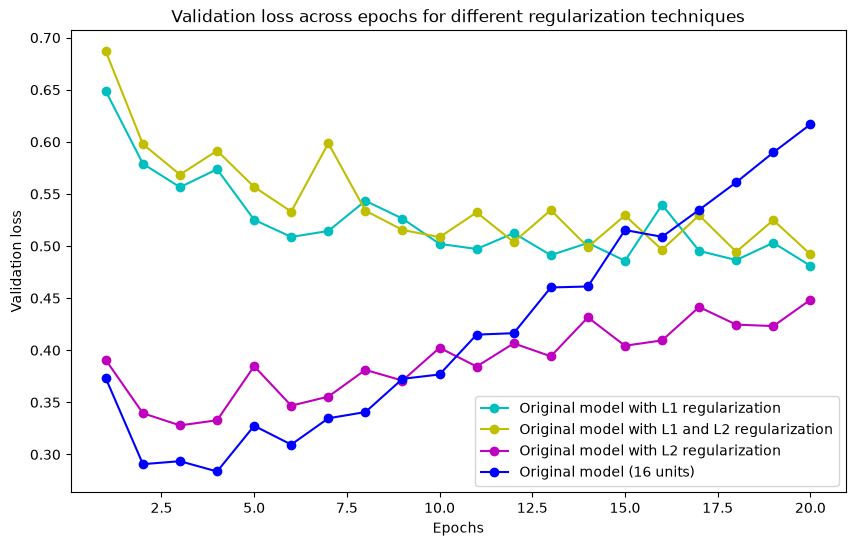

In [19]:
from tensorflow.keras import regularizers
original_model_with_l1 = keras.models.Sequential(layers=[
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l1(0.001), input_shape=(10000,)),
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l1(0.001)),
    keras.layers.Dense(1, activation='sigmoid')
])

original_model_with_l1.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
original_model_with_l1.fit(x_train,y_train,epochs=20,batch_size=512,validation_data=(x_test,y_test))

from tensorflow.keras import regularizers
original_model_with_l1_l2 = keras.models.Sequential(layers=[
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l1_l2(0.001), input_shape=(10000,)),
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l1_l2(0.001)),
    keras.layers.Dense(1, activation='sigmoid')
])

original_model_with_l1_l2.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
original_model_with_l1_l2.fit(x_train,y_train,epochs=20,batch_size=512,validation_data=(x_test,y_test))

validation_loss_with_l1 = original_model_with_l1.history.history['val_loss']
validation_loss_with_l1_l2 = original_model_with_l1_l2.history.history['val_loss']
epochs = range(1, 21)
plt.figure(figsize=(10, 6))
plt.plot(epochs, validation_loss_with_l1, 'c-o', label='Original model with L1 regularization')
plt.plot(epochs, validation_loss_with_l1_l2, 'y-o', label='Original model with L1 and L2 regularization')
plt.plot(epochs, validation_loss_with_l2, 'm-o', label='Original model with L2 regularization')
plt.plot(epochs, original_val_loss, 'b-o', label='Original model (16 units)')
plt.xlabel('Epochs')
plt.ylabel('Validation loss')
plt.title('Validation loss across epochs for different regularization techniques')
plt.legend()
plt.show()

In [74]:
original_model_dropout = keras.models.Sequential(layers=[
    keras.layers.Dense(16, activation='relu', input_shape=(10000,)),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation='sigmoid')
])

original_model_dropout.compile(optimizer='rmsprop',loss='binary_crossentropy',metrics=['accuracy'])
history_dropout = original_model_dropout.fit(x_train,y_train,epochs=20,batch_size=512,validation_data=(x_test,y_test))

#dropout is a method of regularization that randomly sets a fraction of the input units to 0 at each update during training time, which helps prevent overfitting. In this case, we have added dropout layers after each dense layer in the original model, with a dropout rate of 0.5 (meaning that 50% of the input units will be set to 0 during training). This should help improve the generalization performance of the model on the test data. It helps to reduce overfitting because some neurons could use other neurons to learn and in desactivating some neurons, it forces the model to learn more robust features that are useful in conjunction with many different random subsets of the other neurons. This can help prevent the model from relying too heavily on any one feature or combination of features, which can lead to overfitting.


Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - accuracy: 0.6376 - loss: 0.6257 - val_accuracy: 0.8566 - val_loss: 0.4894
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7873 - loss: 0.4847 - val_accuracy: 0.8757 - val_loss: 0.3626
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8473 - loss: 0.3913 - val_accuracy: 0.8830 - val_loss: 0.3065
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8775 - loss: 0.3407 - val_accuracy: 0.8877 - val_loss: 0.2837
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8992 - loss: 0.2916 - val_accuracy: 0.8900 - val_loss: 0.2768
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9099 - loss: 0.2611 - val_accuracy: 0.8895 - val_loss: 0.2797
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9186 - loss: 0.2359 - val_accuracy: 0.8886 - val_loss: 0.2961
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9273 - loss: 0.2203 - val_accuracy: 0.8870 - 

ValueError: x and y must have same first dimension, but have shapes (190,) and (20,)

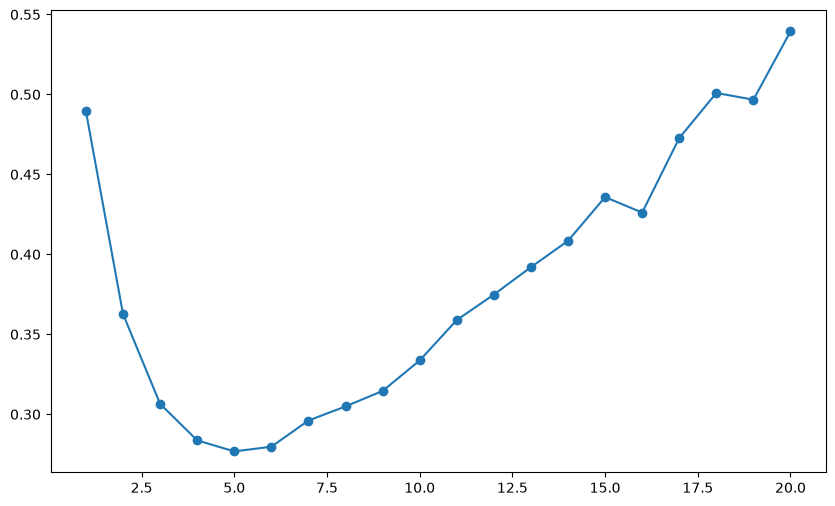

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(history_dropout.history['val_loss']) + 1),
    history_dropout.history['val_loss'],
    marker='o',
    label='Model with Dropout'
)


plt.xlabel('Epochs')
plt.ylabel('Validation loss')
plt.title('Validation loss across epochs: Dropout model')
plt.legend()
plt.grid(True)
plt.show()


In [77]:
#question 16

#The Dropout model achieves its lowest validation loss of approximately 0.28 at epoch 5. After this point, the validation loss gradually increases, reaching approximately 0.54 at epoch 20. This suggests that the model starts to overfit after the fifth epoch.

#Compared with the original model, whose validation loss also increases significantly after its initial minimum, Dropout does not completely prevent overfitting. However, at epoch 20, the Dropout model has a lower validation loss (approximately 0.54) than the original model (approximately 0.62).

#In conclusion, Dropout appears to improve generalization compared with the original model, but overfitting still occurs. Early stopping around epoch 5 could help achieve better validation performance.

In [21]:
from keras.datasets import boston_housing
(train_data2, train_targets), (test_data2, test_targets) = boston_housing.load_data()
print("Training data shape:", train_data2.shape)

Training data shape: (404, 13)


In [22]:
import numpy as np
mean = train_data2.mean(axis=0)
std = train_data2.std(axis=0)
train_data2=(train_data2-mean)/std
test_data2=(test_data2-mean)/std
#we use the same mean and std to normalize the test data, because we want to prevent data leakage. If we were to compute the mean and std of the test data separately, we would be using information from the test set to inform our normalization, which could lead to overfitting and poor generalization performance on new data. By using the mean and std of the training data to normalize both the training and test sets, we ensure that our model is only learning from the training data and is not influenced by any information from the test set.

In [23]:

def build_model():
    model = keras.models.Sequential([
        keras.layers.Input(shape=(train_data2.shape[1],)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(1)
    ])

    model.compile(
        optimizer='rmsprop',
        loss='mse',
        metrics=['mae']
    )

    return model


In [40]:


import numpy as np

k = 4
all_mae_scores = []

# Nombre total d'échantillons
num_samples = len(train_data2)

# Taille de chaque fold, avec gestion des restes
fold_sizes = np.full(k, num_samples // k, dtype=int)
fold_sizes[:num_samples % k] += 1

current = 0

for i in range(k):
    print(f"\nFold {i + 1}/{k}")

    # Sélection des indices de validation
    val_start = current
    val_end = current + fold_sizes[i]

    x_val = train_data2[val_start:val_end]
    y_val = train_targets[val_start:val_end]

    # Données restantes pour l'entraînement
    partial_x_train = np.concatenate(
        [train_data2[:val_start], train_data2[val_end:]],
        axis=0
    )

    partial_y_train = np.concatenate(
        [train_targets[:val_start], train_targets[val_end:]],
        axis=0
    )

    # Création d'un nouveau modèle pour chaque fold
    model = build_model()

    # Entraînement du modèle
    model.fit(
        partial_x_train,
        partial_y_train,
        epochs=100,
        batch_size=1,
        verbose=1
    )

    # Évaluation sur les données de validation
    val_loss, val_mae = model.evaluate(
        x_val,
        y_val,
        verbose=0
    )

    all_mae_scores.append(val_mae)

    print(f"Fold {i + 1} - MAE : {val_mae:.4f}")

    current = val_end

# Affichage des résultats
print("\nMAE pour chaque fold :", all_mae_scores)
print("MAE moyenne :", np.mean(all_mae_scores))
print("Écart-type des MAE :", np.std(all_mae_scores))




Fold 1/4
Epoch 1/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 212.0195 - mae: 10.7589
Epoch 2/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 30.0382 - mae: 3.7757
Epoch 3/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 21.9591 - mae: 3.2199
Epoch 4/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 18.1713 - mae: 2.9089
Epoch 5/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 16.0539 - mae: 2.7294
Epoch 6/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 14.6888 - mae: 2.6130
Epoch 7/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 13.6681 - mae: 2.5252
Epoch 8/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12.9912 - mae: 2.4637
Epoch 9/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12.4634 - mae: 2.4134
Epoch 10/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12.0413 - mae: 2.3658
Epoch 11/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 11.6915 - mae: 2.3317
Epoch 12/100
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 11.4067 - m

In [34]:

import numpy as np

k = 4
num_epochs = 500
num_val_samples = len(train_data2) // k

# Initialiser les historiques et les scores
all_mae_scores_2 = []
all_mae_histories = []

for i in range(k):
    print(f"\nFold {i + 1}/{k}")

    # Définir le fold de validation
    val_start = i * num_val_samples
    val_end = (i + 1) * num_val_samples

    x_val = train_data2[val_start:val_end]
    y_val = train_targets[val_start:val_end]

    # Définir les données d'entraînement
    partial_x_train = np.concatenate(
        [train_data2[:val_start], train_data2[val_end:]],
        axis=0
    )
    partial_y_train = np.concatenate(
        [train_targets[:val_start], train_targets[val_end:]],
        axis=0
    )

    # Construire un nouveau modèle
    model = build_model()

    # Entraîner avec les données de validation
    history = model.fit(
        partial_x_train,
        partial_y_train,
        validation_data=(x_val, y_val),
        epochs=num_epochs,
        batch_size=1,
        verbose=1
    )

    # Enregistrer la MAE de validation à chaque époque
    mae_history = history.history["val_mae"]
    all_mae_histories.append(mae_history)

    # Évaluer le modèle sur le fold de validation
    val_loss, val_mae = model.evaluate(x_val, y_val, verbose=1)
    all_mae_scores_2.append(val_mae)

    print(f"MAE finale du fold : {val_mae:.4f}")
    print(f"Nombre d'époques enregistrées : {len(mae_history)}")

print("\nNombre de folds :", len(all_mae_histories))
print("Époques par fold :", [len(h) for h in all_mae_histories])



Fold 1/4
Epoch 1/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 236.2673 - mae: 11.5557 - val_loss: 37.5593 - val_mae: 3.8158
Epoch 2/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 28.5632 - mae: 3.6579 - val_loss: 23.3933 - val_mae: 3.0097
Epoch 3/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 20.4082 - mae: 3.0092 - val_loss: 18.7696 - val_mae: 2.7532
Epoch 4/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 17.5494 - mae: 2.7355 - val_loss: 16.2879 - val_mae: 2.5943
Epoch 5/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 16.0874 - mae: 2.5839 - val_loss: 14.7593 - val_mae: 2.4963
Epoch 6/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 15.0773 - mae: 2.4943 - val_loss: 13.5900 - val_mae: 2.4159
Epoch 7/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.1900 - mae: 2.4263 - val_loss: 12.5425 - val_mae: 2.3480
Epoch 8/500
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13.4090 - mae: 2.3685 - val_loss: 11.7520 - val_mae: 2.2928
Epoch 9/500
303/303 

In [35]:

# Calculer la MAE moyenne à chaque époque sur les 4 folds
average_mae_history = np.mean(
    np.array(all_mae_histories),
    axis=0
)

# Résultats finaux
final_mae = average_mae_history[-1]

best_epoch = int(np.argmin(average_mae_history)) + 1
best_mae = average_mae_history[best_epoch - 1]

print(f"MAE moyenne à l'époque 500 : {final_mae:.4f}")
print(f"Meilleure MAE moyenne : {best_mae:.4f}")
print(f"Meilleure époque : {best_epoch}")


MAE moyenne à l'époque 500 : 3.1625
Meilleure MAE moyenne : 2.4905
Meilleure époque : 22


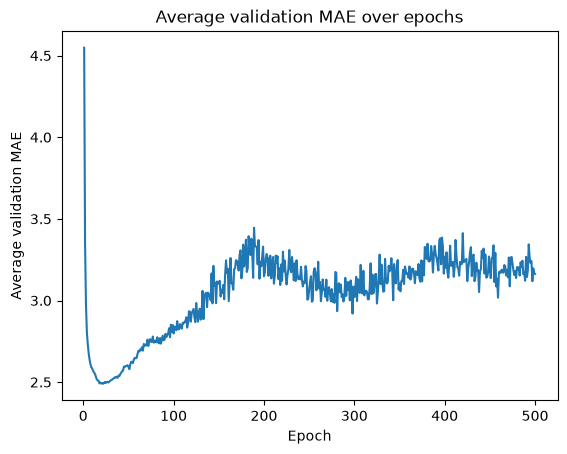

In [37]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(average_mae_history) + 1)

plt.plot(epochs, average_mae_history)
plt.xlabel("Epoch")
plt.ylabel("Average validation MAE")
plt.title("Average validation MAE over epochs")
plt.show()

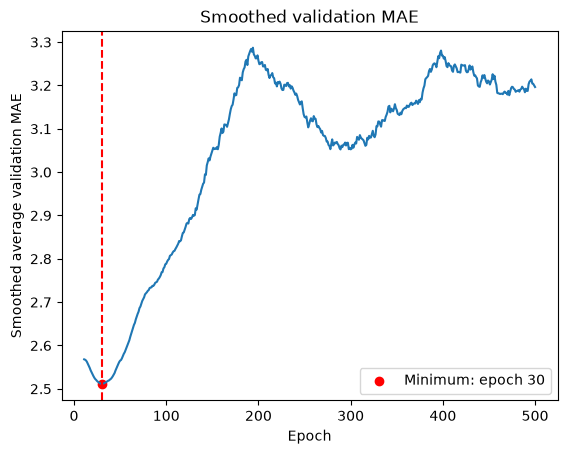

Best epoch: 30
Best smoothed average MAE: 2.5118


In [38]:
def smooth_curve(points, factor=0.9):
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(
                factor * previous + (1 - factor) * point
            )
        else:
            smoothed_points.append(point)
    return smoothed_points


# Supprimer les 10 premières époques, puis lisser
smooth_mae_history = smooth_curve(
    average_mae_history[10:]
)

# Numéro réel des époques restantes : 11 à 500
epochs = np.arange(11, len(average_mae_history) + 1)

# Meilleure époque selon la courbe lissée
best_index = np.argmin(smooth_mae_history)
best_epoch = epochs[best_index]
best_mae = smooth_mae_history[best_index]

# Tracer la courbe lissée et marquer son minimum
plt.plot(epochs, smooth_mae_history)
plt.scatter(
    best_epoch,
    best_mae,
    color="red",
    label=f"Minimum: epoch {best_epoch}"
)
plt.axvline(best_epoch, linestyle="--", color="red")
plt.xlabel("Epoch")
plt.ylabel("Smoothed average validation MAE")
plt.title("Smoothed validation MAE")
plt.legend()
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Best smoothed average MAE: {best_mae:.4f}")

In [42]:
# Construire un nouveau modèle
model = build_model()

# Entraîner sur toutes les données d'entraînement
history_1 = model.fit(
    train_data2,
    train_targets,
    epochs=int(best_epoch),
    batch_size=16,
    verbose=1
)

# Évaluer sur le jeu de test
test_results = model.evaluate(test_data2, test_targets, verbose=0)

# Si build_model() compile avec loss='mse' et metrics=['mae']
test_mse = test_results[0]
test_mae = test_results[1]

print(f"Test MSE: {test_mse:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Average error in dollars: ${test_mae * 1000:.2f}")

Epoch 1/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 514.0289 - mae: 20.7009
Epoch 2/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 339.8915 - mae: 16.3191 
Epoch 3/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 165.4669 - mae: 10.5730 
Epoch 4/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 71.4538 - mae: 6.5245  
Epoch 5/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 42.1779 - mae: 4.9898 
Epoch 6/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 30.5193 - mae: 4.1621 
Epoch 7/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 25.3785 - mae: 3.7075 
Epoch 8/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 22.4885 - mae: 3.4497 
Epoch 9/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 20.2751 - mae: 3.2563 
Epoch 10/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 18.4070 - mae: 3.0887 
Epoch 11/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 16.8521 - mae: 2.9404
Epoch 12/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15.5388 - mae: 2.8100 
Epoch 13/30
26/26 ━

In [ ]:
# Part 3 
import numpy as np

# Calculer la moyenne et l'écart-type sur le train uniquement
mean = train_data2.mean(axis=0)
std = train_data2.std(axis=0)

# Normaliser les données d'entraînement et de test
train_data2 = (train_data2 - mean) / std
test_data2 = (test_data2 - mean) / std




Train data: (404, 13)
Test data: (102, 13)


In [45]:
def build_model(input_dim, optimizer='adam'):
    model = keras.Sequential([
        layers.Dense(64, activation='relu', input_shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [58]:
import numpy as np

def run_kfold_for_optimizer(
    optimizer_name,
    train_data2,
    train_targets,
    k=4,
    num_epochs=200,
    batch_size=16
):
    num_val_samples = len(train_data2) // k

    all_mae_scores = []
    all_mae_histories = []

    for i in range(k):
        print(f"Optimizer: {optimizer_name} | Fold {i + 1}/{k}")

        # Séparer le fold de validation
        val_start = i * num_val_samples
        val_end = (i + 1) * num_val_samples

        x_val = train_data2[val_start:val_end]
        y_val = train_targets[val_start:val_end]

        # Utiliser les autres folds pour l'entraînement
        partial_x_train = np.concatenate(
            [train_data2[:val_start], train_data2[val_end:]],
            axis=0
        )
        partial_y_train = np.concatenate(
            [train_targets[:val_start], train_targets[val_end:]],
            axis=0
        )

        # Créer un nouveau modèle pour chaque fold
        model = build_model(
            input_dim=train_data2.shape[1],
            optimizer=optimizer_name
        )

        # Entraîner et conserver l'historique de validation
        history = model.fit(
            partial_x_train,
            partial_y_train,
            validation_data=(x_val, y_val),
            epochs=num_epochs,
            batch_size=batch_size,
            verbose=0
        )

        # Enregistrer la MAE de chaque époque
        all_mae_histories.append(history.history['val_mae'])

        # Enregistrer la MAE finale du fold
        all_mae_scores.append(history.history['val_mae'][-1])

    # Moyenne des MAE de validation pour chaque époque
    average_mae_history = np.mean(all_mae_histories, axis=0)

    return {
        'optimizer': optimizer_name,
        'mae_scores': all_mae_scores,
        'average_mae_history': average_mae_history
    }

In [63]:
from tensorflow.keras import layers
optimizers = ['sgd', 'adagrad', 'rmsprop', 'adam']

results = {}

for optimizer_name in optimizers:
    results[optimizer_name] = run_kfold_for_optimizer(
        optimizer_name=optimizer_name,
        train_data2=train_data2,
        train_targets=train_targets,
        k=4,
        num_epochs=200,
        batch_size=16
    )

    print(f"\nOptimiseur : {optimizer_name}")
    print("MAE par fold :", results[optimizer_name]['mae_scores'])
    print(
        "MAE moyenne finale :",
        round(
            results[optimizer_name]['average_mae_history'][-1],
            4
        )
    )

Optimizer: sgd | Fold 1/4


c:\Users\allou\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Optimizer: sgd | Fold 2/4
Optimizer: sgd | Fold 3/4
Optimizer: sgd | Fold 4/4

Optimiseur : sgd
MAE par fold : [2.006056785583496, nan, 2.6041817665100098, 2.776430130004883]
MAE moyenne finale : nan
Optimizer: adagrad | Fold 1/4
Optimizer: adagrad | Fold 2/4
Optimizer: adagrad | Fold 3/4
Optimizer: adagrad | Fold 4/4

Optimiseur : adagrad
MAE par fold : [3.364394426345825, 4.487934589385986, 4.2747321128845215, 5.543158531188965]
MAE moyenne finale : 4.4176
Optimizer: rmsprop | Fold 1/4
Optimizer: rmsprop | Fold 2/4
Optimizer: rmsprop | Fold 3/4
Optimizer: rmsprop | Fold 4/4

Optimiseur : rmsprop
MAE par fold : [1.8758080005645752, 2.6238720417022705, 2.7061607837677, 2.512758255004883]
MAE moyenne finale : 2.4296
Optimizer: adam | Fold 1/4
Optimizer: adam | Fold 2/4
Optimizer: adam | Fold 3/4
Optimizer: adam | Fold 4/4

Optimiseur : adam
MAE par fold : [2.305030107498169, 2.449050188064575, 2.2372264862060547, 2.2478487491607666]
MAE moyenne finale : 2.3098


In [64]:
import numpy as np

for optimizer_name, result in results.items():
    scores = result['mae_scores']

    average_mae = np.mean(scores)
    std_mae = np.std(scores)

    print(f"\nOptimizer: {optimizer_name}")
    for i, score in enumerate(scores):
        print(f"  Fold {i + 1}: MAE = {score:.4f}")

    print(f"  Average MAE: {average_mae:.4f}")
    print(f"  Standard deviation: {std_mae:.4f}")


Optimizer: sgd
  Fold 1: MAE = 2.0061
  Fold 2: MAE = nan
  Fold 3: MAE = 2.6042
  Fold 4: MAE = 2.7764
  Average MAE: nan
  Standard deviation: nan

Optimizer: adagrad
  Fold 1: MAE = 3.3644
  Fold 2: MAE = 4.4879
  Fold 3: MAE = 4.2747
  Fold 4: MAE = 5.5432
  Average MAE: 4.4176
  Standard deviation: 0.7748

Optimizer: rmsprop
  Fold 1: MAE = 1.8758
  Fold 2: MAE = 2.6239
  Fold 3: MAE = 2.7062
  Fold 4: MAE = 2.5128
  Average MAE: 2.4296
  Standard deviation: 0.3270

Optimizer: adam
  Fold 1: MAE = 2.3050
  Fold 2: MAE = 2.4491
  Fold 3: MAE = 2.2372
  Fold 4: MAE = 2.2478
  Average MAE: 2.3098
  Standard deviation: 0.0844


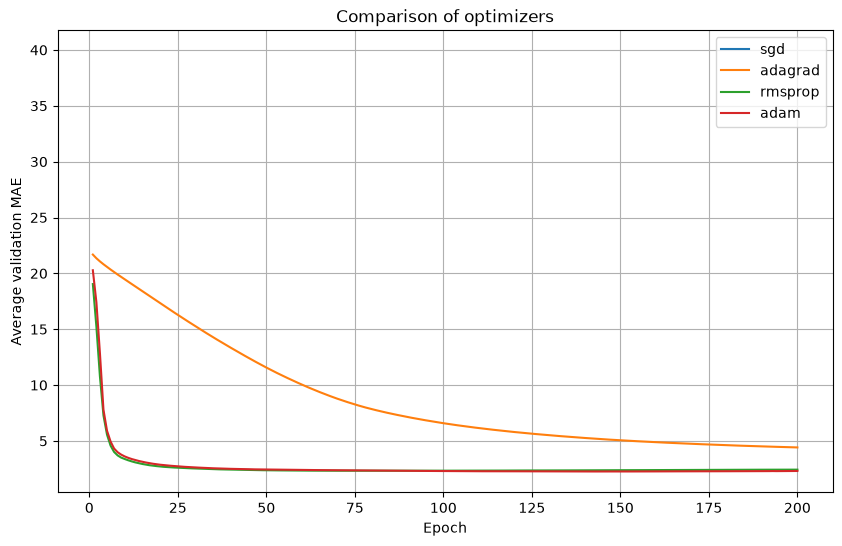

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for optimizer_name, result in results.items():
    mae_history = result['average_mae_history']
    epochs = range(1, len(mae_history) + 1)

    plt.plot(epochs, mae_history, label=optimizer_name)

plt.xlabel("Epoch")
plt.ylabel("Average validation MAE")
plt.title("Comparison of optimizers")
plt.legend()
plt.grid(True)
plt.show()

sgd: optimal epoch = 11, minimum smoothed MAE = nan
adagrad: optimal epoch = 200, minimum smoothed MAE = 4.5080
rmsprop: optimal epoch = 94, minimum smoothed MAE = 2.3342
adam: optimal epoch = 155, minimum smoothed MAE = 2.2664


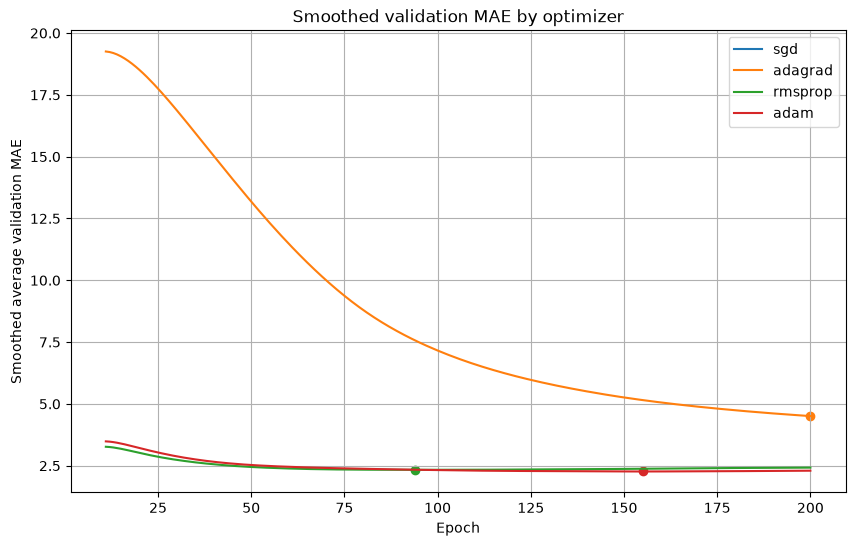

In [66]:
def smooth_curve(points, factor=0.9):
    smoothed_points = []

    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(
                factor * previous + (1 - factor) * point
            )
        else:
            smoothed_points.append(point)

    return smoothed_points


plt.figure(figsize=(10, 6))

optimal_results = {}

for optimizer_name, result in results.items():

    # Ignorer les 10 premières époques, puis lisser
    mae_history = result['average_mae_history']
    smoothed_mae = smooth_curve(mae_history[10:])

    # Les époques commencent à 11 après suppression des 10 premières
    epochs = np.arange(11, len(mae_history) + 1)

    # Trouver le minimum de la courbe lissée
    best_index = np.argmin(smoothed_mae)
    best_epoch = int(epochs[best_index])
    best_mae = smoothed_mae[best_index]

    optimal_results[optimizer_name] = {
        'best_epoch': best_epoch,
        'best_mae': best_mae
    }

    # Tracer la courbe et marquer le minimum
    plt.plot(epochs, smoothed_mae, label=optimizer_name)
    plt.scatter(best_epoch, best_mae)

    print(
        f"{optimizer_name}: "
        f"optimal epoch = {best_epoch}, "
        f"minimum smoothed MAE = {best_mae:.4f}"
    )

plt.xlabel("Epoch")
plt.ylabel("Smoothed average validation MAE")
plt.title("Smoothed validation MAE by optimizer")
plt.legend()
plt.grid(True)
plt.show()

In [70]:
import numpy as np

test_results = {}

for optimizer_name in results.keys():

    # Nombre d'époques optimal trouvé à la question 7
    best_epoch = optimal_results[optimizer_name]['best_epoch']

    print(f"\nOptimizer: {optimizer_name}")
    print(f"Training for {best_epoch} epochs...")

    # Construire un nouveau modèle
    model = build_model(
        input_dim=train_data2.shape[1],
        optimizer=optimizer_name
    )

    # Entraîner sur toutes les données d'entraînement
    model.fit(
        train_data2,
        train_targets,
        epochs=best_epoch,
        batch_size=16,
        verbose=1
    )

    # Évaluer sur le jeu de test
    evaluation = model.evaluate(test_data2, test_targets, verbose=1)

    mse = evaluation[0]
    mae = evaluation[1]

    test_results[optimizer_name] = {
        'mse': mse,
        'mae': mae,
        'epochs': best_epoch
    }

    print(f"Test MSE: {mse:.4f}")
    print(f"Test MAE: {mae:.4f}")


Optimizer: sgd
Training for 11 epochs...
Epoch 1/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 411.1259 - mae: 15.6656
Epoch 2/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan         
Epoch 3/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 4/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 5/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 6/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 7/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan
Epoch 8/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 9/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan
Epoch 10/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: nan - mae: nan
Epoch 11/11
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - loss: nan - mae: nan
Test MSE: nan
Test MAE: nan

Optimizer: adagrad
Training for 200 epochs..

In [71]:
ranking = sorted(
    test_results.items(),
    key=lambda item: item[1]['mae']
)

print("Ranking of optimizers (best to worst):")

for rank, (optimizer_name, metrics) in enumerate(ranking, start=1):
    print(
        f"{rank}. {optimizer_name.upper()} "
        f"- Test MAE: {metrics['mae']:.4f}, "
        f"Test MSE: {metrics['mse']:.4f}, "
        f"Epochs: {metrics['epochs']}"
    )

    

Ranking of optimizers (best to worst):
1. ADAM - Test MAE: 2.3904, Test MSE: 13.4551, Epochs: 155
2. RMSPROP - Test MAE: 2.6444, Test MSE: 17.1884, Epochs: 94
3. SGD - Test MAE: nan, Test MSE: nan, Epochs: 11
4. ADAGRAD - Test MAE: 4.5764, Test MSE: 35.6382, Epochs: 200
